# Simulating Nuclear Fission Chain Reactions
## Henry O'Rorke

## Introduction:
Nuclear fission is the splitting of a heavy nucleus after it absorbs a neutron. It is one of the most significant discoveries in
physics. It was first achieved experimentally by Hahn and Strassmann in 1938 and explained by Meitner and Frisch shortly after.
 
In this project, I will simulate fission chain reactions using a Monte Carlo model of neutron's motion, where individual 
neutrons are tracked probabilistically through a fissile material as they scatter, get absorbed, trigger more fission, or escape the material. The focus will be on the neutron multiplication factor k, which determines whether a chain reaction dies out, sustains itself, or grows exponentially (depending on if it is less than, greater than, or equal to 1.)

## Table of Contents

**1. Fission**
- 1.1: Nuclear Binding Energy
- 1.2: Mass-Energy Equivalence and Q-Value
- 1.3: Why Uranium Fissions and Iron Doesn't

**2. Monte Carlo Neutron Transport**
- 2.1: Cross Sections and Mean Free Path
- 2.2: Monte Carlo Simulation
- 2.3: Plotting Neutron Paths

**3. Criticality**
- 3.1: Running a Full Generation
- 3.2: Computing k and Finding Critical Radius and Mass

**4. Enrichment**
- 4.1: Natural vs. Reactor vs. Weapon Grade Uranium

## Section 1: Fission

### 1.1: Nuclear Binding Energy

The stability of a nucleus is determined by its binding energy, defined as the energy 
required to completely disassemble a nucelus into individual free nucleons. 
A large binding energy means the nucleus is tightly bound and stable.

Instead of total binding energy, binding energy per nucleon is more commonly used:

$$BE/A = \frac{\text{Total Binding Energy}}{\text{Number of Nucleons}}$$

This allows fair comparison across nuclei of different sizes. The binding energy 
curve has a consistent pattern: stability increases from hydrogen up to 
$^{56}_{26}\text{Fe}$, which sits at the peak at 8.79 MeV/nucleon, then 
gradually decreases for heavier elements.

Iron-56 is the most stable nucleus. It represents the perfect 
balance between the strong nuclear force, which is an extremely short range force that
attracts nucleons close to each other, and the electromagnetic force, which 
repels protons from each other at all ranges. For heavier nuclei past iron, each additional 
nucleon adds more electromagnetic repulsion than strong force attraction, reducing stability.

This curve is the foundation of nuclear physics. Any reaction that moves 
nuclei toward the iron peak releases energy:

- Fusion: light nuclei on the left side of the curve combine and move 
  right toward iron, releasing energy
- Fission: heavy nuclei on the right side split into lighter fragments 
  that land closer to iron, releasing energy

Any reaction moving away from iron in either direction requires energy input rather than releasing it.

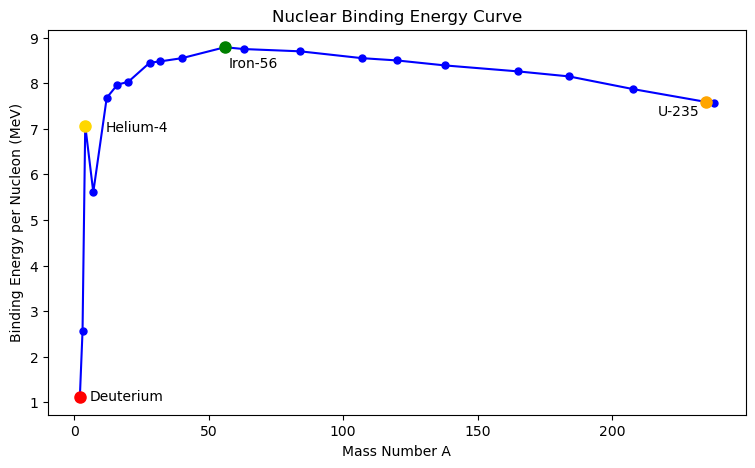

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random

# binding energy per nucleon data (mass number A, binding energy in MeV)
# values from the Atomic Mass Evaluation (AME2020)
binding_data = [(2,  1.11), (3,  2.57), (4,  7.07), (7,  5.61),
    (12, 7.68), (16, 7.97), (20, 8.03), (28, 8.45),
    (32, 8.48), (40, 8.55), (56, 8.79), (63, 8.75),
    (84, 8.70), (107, 8.55), (120, 8.50), (138, 8.39),
    (165, 8.26), (184, 8.15), (208, 7.87), (235, 7.59),
    (238, 7.57)]

A_vals = [i[0] for i in binding_data]
BE_vals = [i[1] for i in binding_data]

plt.figure(figsize = (9, 5))
plt.plot(A_vals, BE_vals, 'o-', color = 'blue', markersize = 5)

# key points
plt.plot(2, 1.11, 'o', color = 'red', markersize = 8)
plt.plot(4, 7.07, 'o', color = 'gold', markersize = 8)
plt.plot(56, 8.79, 'o', color = 'green', markersize = 8)
plt.plot(235, 7.59, 'o', color = 'orange', markersize = 8)

# labels
plt.text(5.8, 1.05, 'Deuterium', fontsize = 10)
plt.text(11.5, 6.95, 'Helium-4', fontsize = 10)
plt.text(57.5, 8.35, 'Iron-56', fontsize = 10)
plt.text(217, 7.3, 'U-235', fontsize = 10)

plt.xlabel('Mass Number A')
plt.ylabel('Binding Energy per Nucleon (MeV)')
plt.title('Nuclear Binding Energy Curve')
plt.show()

### 1.2: Mass-Energy Equivalence and Q-Value

Every nuclear reaction either releases or absorbs energy depending on whether 
the products are more or less tightly bound than the reactants. The energy 
released is given by Einstein's mass-energy equivalence:

$$E = \Delta m c^2$$

where $\Delta m$ is the mass difference between reactants and products. In 
nuclear physics this is expressed as the Q-value:

$$Q = (m_{\text{reactants}} - m_{\text{products}}) \times 931.494 \ \text{MeV/u}$$

If $Q > 0$, mass was converted to energy and the reaction releases energy.
If $Q < 0$, energy must be supplied for the reaction to occur.

A typical U-235 fission event goes as:

$$^{235}_{92}\text{U} + n \rightarrow ^{141}_{56}\text{Ba} + ^{92}_{36}\text{Kr} + 3n$$

In [36]:
# Atomic masses in u
# 1 u = 931.494 MeV/c^2
u_to_MeV = 931.494
m_U235 = 235.043930
m_n = 1.008665
m_Ba141 = 140.914411
m_Kr92 = 91.926156

mass_reactants = m_U235 + m_n
mass_products = m_Ba141 + m_Kr92 + 3*m_n
delta_m = mass_reactants - mass_products
Q = delta_m * u_to_MeV

print(f"Mass of reactants: {round(mass_reactants, 4)} u")
print(f"Mass of products: {round(mass_products, 4)} u")
print(f"Mass difference: {round(delta_m, 4)} u")
print(f"Q-value: {round(Q, 2)} MeV")

Mass of reactants: 236.0526 u
Mass of products: 235.8666 u
Mass difference: 0.186 u
Q-value: 173.29 MeV


### 1.3: Why Uranium Fissions and Iron Doesn't

The binding energy curve explains why fission is only useful for heavy elements. 
For a reaction to be exothermic ($Q > 0$), the products must be more tightly bound 
per nucleon than the reactants.

$^{235}_{92}\text{U}$ sits at roughly 7.6 MeV/nucleon. When it fissions, the two 
daughter nuclei reach roughly 8.5 MeV/nucleon, a significant jump toward the iron 
peak, releasing approximately 200 MeV per fission event.

For $^{56}_{26}\text{Fe}$, any split would move the daughter nuclei away from the 
peak in both directions, making the products less tightly bound than the original 
nucleus. This means $Q < 0$ and the reaction would require energy input rather than 
releasing it. Iron-56 sits at the maximum of the binding energy curve at 8.79 
MeV/nucleon, making it the most stable nucleus that can exist. It is the endpoint 
of energy release in both fusion and fission.

This is why only heavy elements like $^{235}_{92}\text{U}$ and $^{239}_{94}\text{Pu}$ 
are practical for fission. They sit far enough to the right of the iron peak that 
their fission products land near the peak, releasing large amounts of energy in 
the process.

## Section 2: Monte Carlo Neutron Transport

### 2.1: Cross Sections and Mean Free Path

When a neutron travels through uranium, it can interact with a nucleus in 
three ways:

- Fission: the neutron is absorbed and the nucleus splits, releasing 
  energy and more neutrons
- Radiative capture: the neutron is absorbed but no fission occurs, 
  so the neutron is lost and gamma rays are emitted
- Scattering: the neutron bounces off the nucleus and continues in a 
  new random direction

The probability of each interaction is described by a cross section $\sigma$, 
measured in barns ($1 \ \text{barn} = 10^{-24} \ \text{cm}^2$). A larger cross 
section means a higher probability of that interaction occurring.

From the cross sections, the mean free path $\lambda$ can be derived, which is the 
average distance a neutron travels before interacting with a nucleus:

$$\lambda = \frac{1}{n \sigma}$$

where $n$ is the number density (nuclei per $\text{cm}^3$) and $\sigma$ is the 
total cross section, given by:

$$\sigma_{total} = \sigma_{fission} + \sigma_{capture} + \sigma_{scatter}$$

In [37]:
# 1 barn = 1e-24 cm^2
barn = 1e-24

# Na
N_avogadro = 6.022e23 # nuclei/mol

# U-235 material properties
density = 19.1 # g/cm^3
molar_mass = 235.0 # g/mol

# U-235 fast neutron cross sections(in barns, converted to cm^2)
sigma_fission = 1.235 * barn 
sigma_capture = 0.090 * barn
sigma_scatter = 4.566 * barn 
sigma_total = sigma_fission + sigma_capture + sigma_scatter

# branching probabilities for each interaction type
p_fission = sigma_fission / sigma_total
p_capture = sigma_capture / sigma_total
p_scatter = sigma_scatter / sigma_total

# number of U-235 nuclei per cm^3
number_density = (density * N_avogadro) / molar_mass

# mean free path
mean_free_path = 1.0 / (number_density * sigma_total)

print(f"Total cross section: {round(sigma_total / barn, 3)} barns")
print(f"Number density: {round(number_density, 3)} nuclei/cm^3")
print(f"Mean free path: {round(mean_free_path, 3)} cm")
print(f"P(fission): {round(p_fission * 100, 2)}%")
print(f"P(capture): {round(p_capture * 100, 2)}%")
print(f"P(scatter): {round(p_scatter * 100, 2)}%")

Total cross section: 5.891 barns
Number density: 4.894476595744682e+22 nuclei/cm^3
Mean free path: 3.468 cm
P(fission): 20.96%
P(capture): 1.53%
P(scatter): 77.51%


### 2.2 Monte Carlo Simulation

To simulate neutron transport, I used a Monte Carlo method to model individual neutrons 
probabilistically and observe their behavior.

Each neutron is initially given a random direction. The distance the neutron travels before its next 
interaction is based on an exponential distribution:

$$d = -\lambda \ln(u)$$

where $u$ is a random number between 0 and 1 and $\lambda$ is the mean 
free path. This distribution demonstartes how at any point along its path, the neutron 
has the same probability per unit length of interacting, regardless of how far it has already traveled.

Once the neutron reaches its endpoint, I determined the interaction type by 
sampling a random number and comparing it to the interction probabilities:

$$P(\text{fission}) = \frac{\sigma_f}{\sigma_{total}}, \quad 
P(\text{capture}) = \frac{\sigma_c}{\sigma_{total}}, \quad 
P(\text{scatter}) = \frac{\sigma_s}{\sigma_{total}}$$

If the neutron's endpoint falls outside the sphere radius, it is counted as an 
escape.

In [38]:
def transport_neutron(x, y, z, radius):
    
    # random neutron motion
    dx = random.uniform(-1, 1)
    dy = random.uniform(-1, 1)
    dz = random.uniform(-1, 1)
    
    # normalize vectors
    length = (dx**2 + dy**2 + dz**2)**0.5
    dx = dx / length
    dy = dy / length
    dz = dz / length
    
    # estimated flight distance from exponential distribution (e^(-d/λ))/λ
    distance = -mean_free_path * math.log(random.uniform(0, 1))
    
    # final positions
    x_end = x + distance * dx
    y_end = y + distance * dy
    z_end = z + distance * dz
    
    # check if neutron escaped the sphere
    r_end = (x_end**2 + y_end**2 + z_end**2)**0.5
    
    # generate random number between 0 & 1 to determine interaction type
    probability = random.uniform(0, 1)
    
    if r_end > radius:
        return 'escape', x_end, y_end, z_end
    elif probability < p_fission:
        return 'fission', x_end, y_end, z_end
    elif probability < p_fission + p_capture:
        return 'capture', x_end, y_end, z_end
    else:
        return 'scatter', x_end, y_end, z_end

### 2.3: Plotting Neutron Paths

To visualize the simulation, I tracked 50 neutrons each starting from the center 
of the sphere and plotted their paths projected onto the xy-plane. The sphere boundary 
is drawn as a circle of radius 8.7 cm, which is approximately the critical radius 
of pure $^{235}_{92}\text{U}$ - the point at which a chain reaction can sustain 
itself.

Each neutron travels in a straight line until its first interaction, shown as a 
grey line, with a colored dot marking the interaction point. Green indicates fission, 
red indicates escape, blue indicates capture, and grey indicates scattering.

This plot shows only a single generation - scattered neutrons are not tracked 
further. Interaction probabilities $P(\text{fission})$, $P(\text{capture})$, and $P(\text{scatter})$
are fixed material properties, but the probability of escape is geometry-dependent. 
A neutron near the boundary is much more likely to escape on its next step than one near 
the center, which is why the multi-generation simulation in Section 3 is included. 

The plot is a 2D projection of a 3D simulation, so some escaped neutrons may 
appear inside the circle boundary due to a large $z$-component that is not visible 
in the projection.

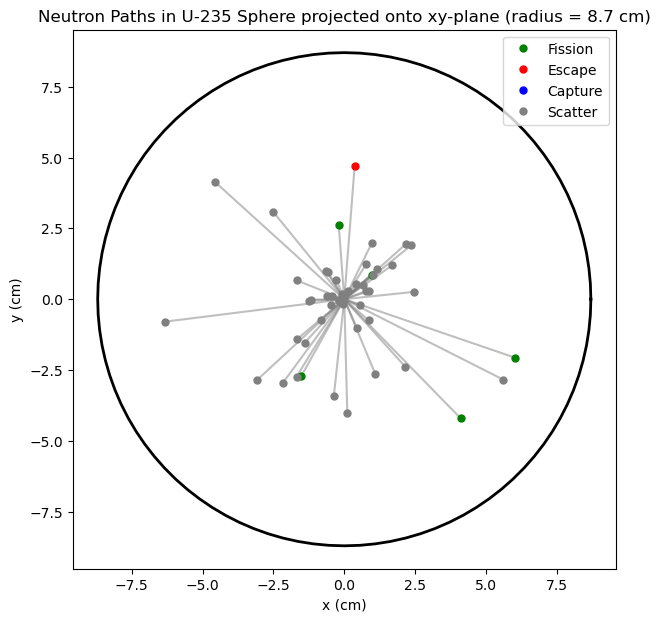

n = 100
 Fission: 13.0% (theoretical: 21.0%)
 Capture: 2.0% (theoretical: 1.5%)
 Scatter: 76.0% (theoretical: 77.5%)
 Escape: 9.0%

n = 500
 Fission: 19.0% (theoretical: 21.0%)
 Capture: 1.4% (theoretical: 1.5%)
 Scatter: 71.8% (theoretical: 77.5%)
 Escape: 7.8%

n = 1000
 Fission: 18.3% (theoretical: 21.0%)
 Capture: 1.7% (theoretical: 1.5%)
 Scatter: 72.3% (theoretical: 77.5%)
 Escape: 7.7%



In [39]:
def plot_neutron_paths(radius, n_neutrons):
    
    plt.figure(figsize=(7, 7))
    
    angles = [2 * math.pi * i / 100 for i in range(101)]
    circle_x = [radius * math.cos(a) for a in angles]
    circle_y = [radius * math.sin(a) for a in angles]
    plt.plot(circle_x, circle_y, 'k-', linewidth = 2)
    
    fission_x, fission_y = [], []
    escape_x, escape_y = [], []
    capture_x, capture_y = [], []
    scatter_x, scatter_y = [], []
    
    for i in range(n_neutrons):
        xi, yi, zi = 0.0, 0.0, 0.0
        outcome, x_new, y_new, z_new = transport_neutron(xi, yi, zi, radius)
        
        if outcome == 'fission':
            fission_x.append(x_new)
            fission_y.append(y_new)
        elif outcome == 'escape':
            escape_x.append(x_new)
            escape_y.append(y_new)
        elif outcome == 'capture':
            capture_x.append(x_new)
            capture_y.append(y_new)
        else:
            scatter_x.append(x_new)
            scatter_y.append(y_new)
        
        plt.plot([xi, x_new], [yi, y_new], color = 'gray', alpha = 0.5)
    
    plt.plot(fission_x, fission_y, 'o', color ='green', markersize = 5, label = 'Fission')
    plt.plot(escape_x, escape_y, 'o', color = 'red', markersize = 5, label = 'Escape')
    plt.plot(capture_x, capture_y, 'o', color = 'blue', markersize = 5, label = 'Capture')
    plt.plot(scatter_x, scatter_y, 'o', color = 'grey', markersize = 5, label = 'Scatter')
    
    plt.xlabel('x (cm)')
    plt.ylabel('y (cm)')
    plt.title(f'Neutron Paths in U-235 Sphere projected onto xy-plane (radius = {radius} cm)')
    plt.axis('equal')
    plt.legend()
    plt.show()

plot_neutron_paths(8.7, 50)

# repeat the simulation and track outcome percentages
for n in [100, 500, 1000]:
    counts = {'fission': 0, 'escape': 0, 'capture': 0, 'scatter': 0}
    for i in range(n):
        outcome, x_new, y_new, z_new = transport_neutron(0.0, 0.0, 0.0, 8.7)
        counts[outcome] += 1
    print(f"n = {n}")
    print(f" Fission: {round(counts['fission'] / n * 100, 1)}% (theoretical: {round(p_fission * 100, 1)}%)")
    print(f" Capture: {round(counts['capture'] / n * 100, 1)}% (theoretical: {round(p_capture * 100, 1)}%)")
    print(f" Scatter: {round(counts['scatter'] / n * 100, 1)}% (theoretical: {round(p_scatter * 100, 1)}%)")
    print(f" Escape: {round(counts['escape'] / n * 100, 1)}%")
    print()

## Section 3: Criticality 

### 3.1 Running a Full Generation

The neutron multiplication factor $k$ determines the outcome of a chain reaction:

$$k = \frac{\text{neutrons in generation } n+1}{\text{neutrons in generation } n}$$

- $k < 1$: subcritical - the reaction dies out
- $k = 1$: critical - the reaction sustains itself
- $k > 1$: supercritical - the reaction grows exponentially

To compute $k$, I simulated a full generation of neutron transport. Every 
neutron in the current population is transported through the material using 
the transport_neutron function. The outcomes of their interactions determine the next generation:

- Fission: produces 2 or 3 new neutrons at the site of fission, with each outcome
  roughly equally likely, as the average neutron yield for U-235 is 2.44.
- Scatter: the neutron survives and continues from its new position
- Capture or escape: the neutron is permanently lost

In [40]:
def run_generation(positions, radius):
    
    new_positions = []
    
    for pos in positions: 
        x, y, z = pos[0], pos[1], pos[2]
        outcome, x_new, y_new, z_new = transport_neutron(x, y, z, radius)
        if outcome == 'fission':
            n_new = random.choice([2, 3])
            for n in range(n_new):
                new_positions.append([x_new, y_new, z_new])
        elif outcome == 'scatter':
            new_positions.append([x_new, y_new, z_new])
    
    return new_positions

### 3.2 Computing k and Finding Critical Radius and Mass

A single generation gives an uncertain estimate of $k$ due to randomness in a small sample size. 
To get a stable estimate, I ran 20 generations and found the average value of $k$ across all of them. 
The statistical uncertainty of a Monte Carlo estimate goes according to:

$$\sigma \propto \frac{1}{\sqrt{N}}$$

so averaging over more generations and using more neutrons both improve the estimate.

To find the critical radius, I looped over 25 sphere radii and computed $k$ at each one. At small 
radii the sphere is even smaller than the mean free path $\lambda = 1.73$ cm, so most neutrons 
escape before interacting, pushing $k$ below 1. As the radius increases, fewer neutrons escape 
and more fissions occur, until $k$ crosses 1 at the critical radius — the minimum size at which 
a self-sustaining chain reaction is possible in pure $^{235}_{92}\text{U}$.

Once the critical radius is known, the critical mass follows directly from the density of uranium 
metal $\rho = 18.71 \ \text{g/cm}^3$:

$$m_{critical} = \rho \cdot \frac{4}{3}\pi r_{critical}^3$$

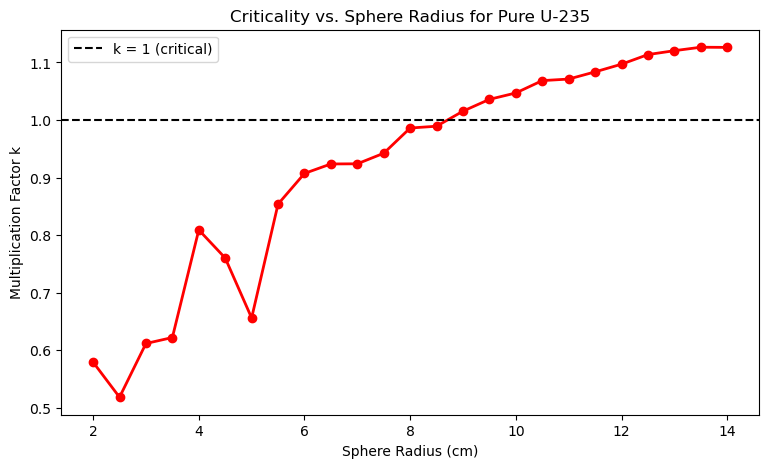

In [41]:
def compute_k(radius, n_initial, n_generations):
    
    # place starting neutrons at random positions inside the sphere
    positions = []
    while len(positions) < n_initial:
        x = random.uniform(-radius, radius)
        y = random.uniform(-radius, radius)
        z = random.uniform(-radius, radius)
        if (x**2 + y**2 + z**2)**0.5 < radius: positions.append([x, y, z])
    
    k_values = []
    
    for i in range(n_generations):
        if len(positions) == 0:
            k_values.append(0)
            break
        new_positions = run_generation(positions, radius)
        k = len(new_positions) / len(positions)
        k_values.append(k)
        positions = new_positions
        # limit to neutron growth
        if len(positions) > 5000:
            positions = positions[:5000]
    
    return sum(k_values) / len(k_values)

# loop over sphere radii 
radii = [2 + i * 0.5 for i in range(25)]
k_values = [compute_k(r, 200, 20) for r in radii]

plt.figure(figsize = (9, 5))
plt.plot(radii, k_values, 'o-', color = 'red', linewidth = 2)
plt.axhline(y = 1.0, color = 'black', linestyle = '--', label = 'k = 1 (critical)')
plt.xlabel('Sphere Radius (cm)')
plt.ylabel('Multiplication Factor k')
plt.title('Criticality vs. Sphere Radius for Pure U-235')
plt.legend()
plt.show()

## Section 4: Enrichment

### 4.1: Natural vs. Reactor vs. Weapon Grade Uranium

Natural uranium is only 0.7% U-235, with the rest being U-238. Unlike 
U-235, U-238 cannot sustain a fission chain reaction - it has a total fast fission 
cross section of zero and instead absorbs neutrons through 
radiative capture, removing them from the chain reaction.

The enrichment level determines how much U-235 and U-238 is present:

- Natural uranium (0.7% U-235): subcritical with fast or thermal neutrons
- Reactor grade (3-5% U-235): critical only with a moderator like water to slow neutrons and increase cross sections
- Weapon grade (>90% U-235): critical with fast neutrons - cross sections computed in 2.1

To model enrichment, the cross sections of U-235 and U-238 must be mixed and weighted by 
their concentrations:

$$\sigma_{mixed} = e \cdot \sigma_{235} + (1-e) \cdot \sigma_{238}$$

where $e$ is the enrichment fraction (concentration). This gives new interaction probabilities and 
a new mean free path for the mixed material, which are then used to compute $k$ 
at a fixed radius of 8.7 cm from near zero to 100% enrichment.

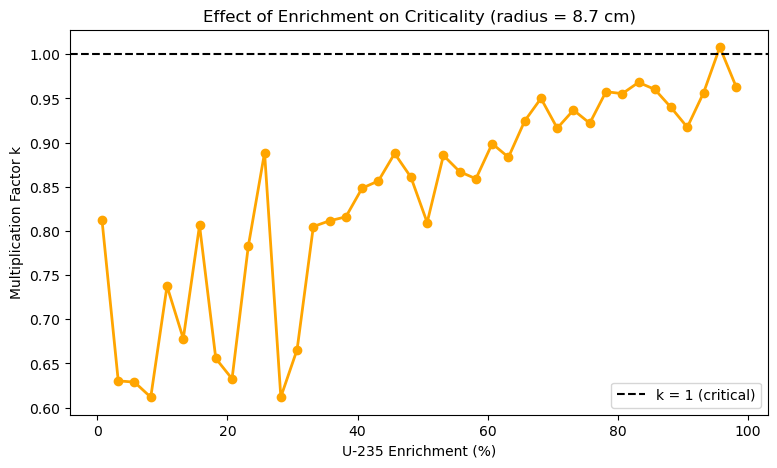

In [42]:
def compute_k_enrichment(radius, enrichment, n_initial, n_generations):
    
    # U-238 cross sections
    sigma_fission_238 = 0.0
    sigma_capture_238 = 0.36 * barn
    sigma_scatter_238 = 4.8 * barn
    
    # mix cross sections based on enrichment fraction
    e = enrichment
    sf = e * sigma_fission + (1 - e) * sigma_fission_238
    sc = e * sigma_capture + (1 - e) * sigma_capture_238
    ss = e * sigma_scatter + (1 - e) * sigma_scatter_238
    st = sf + sc + ss
    
    # recalculate probabilities and mean free path for given enrichment
    pf = sf / st
    pc = sc / st
    ps = ss / st
    mfp = 1.0 / (number_density * st)
    
    # place starting neutrons at random positions inside the sphere
    positions = []
    while len(positions) < n_initial:
        x = random.uniform(-radius, radius)
        y = random.uniform(-radius, radius)
        z = random.uniform(-radius, radius)
        if (x**2 + y**2 + z**2)**0.5 < radius:
            positions.append([x, y, z])
    
    k_vals = []
    
    for i in range(n_generations):
        if len(positions) == 0:
            k_vals.append(0)
            break
        new_positions = []
        for pos in positions:
            x, y, z = pos[0], pos[1], pos[2]
            
            # transport with enrichment cross sections
            dx = random.uniform(-1, 1)
            dy = random.uniform(-1, 1)
            dz = random.uniform(-1, 1)
            length = (dx**2 + dy**2 + dz**2)**0.5
            dx = dx / length 
            dy = dy / length 
            dz = dz / length
            distance = -mfp * math.log(random.random())
            x_new = x + distance * dx
            y_new = y + distance * dy
            z_new = z + distance * dz
            r_new = (x_new**2 + y_new**2 + z_new**2)**0.5
            prob = random.uniform(0, 1)
            
            if r_new > radius:
                pass
            elif prob < pf:
                neutron_new = random.choice([2, 3])
                for n in range(neutron_new):
                    new_positions.append([x_new, y_new, z_new])
            elif prob < pf + pc:
                pass
            else:
                new_positions.append([x_new, y_new, z_new])
        
        k_vals.append(len(new_positions) / len(positions))
        positions = new_positions
        # limit to neutron growth 
        if len(positions) > 5000:
            positions = positions[:5000]
    
    return sum(k_vals) / len(k_vals)

enrichments = [0.007 + i * 0.025 for i in range(40)]
k_enrich = [compute_k_enrichment(8.7, e, 200, 20) for e in enrichments]

plt.figure(figsize=(9, 5))
plt.plot([e * 100 for e in enrichments], k_enrich, 'o-', color = 'orange', linewidth = 2)
plt.axhline(1.0, color = 'black', linestyle = '--', label = 'k = 1 (critical)')
plt.xlabel('U-235 Enrichment (%)')
plt.ylabel('Multiplication Factor k')
plt.title('Effect of Enrichment on Criticality (radius = 8.7 cm)')
plt.legend()
plt.show()